# 模型解释：特征系数、时间权重和信息贡献

先完整运行前四本Notebook。本Notebook读取已保存的模型和结果，不拟合或选择新模型。

“权重”需要分别看：

1. **逻辑回归系数**：数值输入已经标准化，每个特征有主胜、平局、客胜三个系数。系数不是重要性百分比。
2. **时间权重**：近期90天、交锋365天半衰期，为预先固定的规则。LSTM也用该规则汇总隐藏向量，不是学习出的注意力。
3. **LSTM信息贡献**：使用之前已经训练的完整模型与减少输入的模型比较。没有一个可直接解释为“近期占60%、交锋占40%”的网络参数。
4. **多任务λ**：调节赛果损失与赔率损失的训练比例，不是特征权重。

结果保存到 `reports/post_analysis/`。这里是已查看测试集后的描述性解释，不据此在同一测试集上删特征、重新调参并声称独立验证。

## 1. 读取已有文件

In [1]:
from pathlib import Path
import json
from datetime import timedelta
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from IPython.display import display

ROOT=Path.cwd()
if not (ROOT/'data/processed/baseline_features.csv').exists():ROOT=ROOT.parent
OUT=ROOT/'reports/post_analysis';OUT.mkdir(parents=True,exist_ok=True)
SEED=20261028
FEATURE_LABELS={
'elo_diff':'Elo差','h2h_count':'交锋场数','h2h_missing':'无交锋标记',
'recent_ppg_diff':'近期场均积分差','recent_gd_diff':'近期场均净胜球差','recent_draw_rate_mean':'近期平局率均值',
'h2h_ppg_diff':'交锋场均积分差','h2h_gd':'交锋场均净胜球','h2h_draw_rate':'交锋平局率',
'q_log_H_D':'赔率主胜/平局对数比','q_log_A_D':'赔率客胜/平局对数比'}
F=['recent_ppg_diff','recent_gd_diff','recent_draw_rate_mean']
H=['h2h_ppg_diff','h2h_gd','h2h_draw_rate']
B=['elo_diff','h2h_count','h2h_missing']
Q=['q_log_H_D','q_log_A_D']
frames={name:pd.read_csv(ROOT/f'data/processed/{file}',parse_dates=['MatchDate']) for name,file in [('baseline','baseline_features.csv'),('time_decay','time_decay_features.csv')]}
for frame in frames.values():
    assert frame.SourceRow.is_unique
np.testing.assert_array_equal(frames['baseline'].SourceRow,frames['time_decay'].SourceRow)
features=frames['baseline'];test=features.loc[features.split.eq('test')].reset_index(drop=True)
selection=json.loads((ROOT/'reports/lstm_multitask/selection.json').read_text())
print('测试比赛数：',len(test),'；只解释已训练模型。')

测试比赛数： 11772 ；只解释已训练模型。


## 2. 导出全部22个逻辑回归模型的系数

设 `z_H,z_D,z_A` 是三个线性分数，概率通过softmax计算。解释主胜相对客胜时，使用：

`log(p_H/p_A) = z_H-z_A`。

因此数值特征增加1个训练集标准差，其主胜/客胜概率比乘以 `exp(beta_H-beta_A)`，假设其他输入固定。它不是主胜概率增加相同百分比，也不是因果效果。

每个特征保存三个系数及三种类别对比，避免仅看H−A而遗漏平局信息。数值特征按三个类别对比的均方根排序，只是系数大小的描述，不等于移除该特征后的损失变化。联赛独热列没有标准化，单独输出，不与数值列混排。联赛的解释使用相对E0的差值。

In [2]:
coefficient_rows=[];intercept_rows=[];division_rows=[];bundles={}
for family,frame in frames.items():
    candidates=sorted((ROOT/f'reports/{family}/models').glob('*.joblib'))
    for path in candidates:
        bundle=joblib.load(path);name=path.stem;bundles[name]=(family,bundle)
        prep,model=bundle['preprocessor'],bundle['model']
        assert np.array_equal(model.classes_,[0,1,2])
        columns=bundle['spec']['columns'];n=len(columns)
        scaler=prep.named_transformers_['numeric']
        names=prep.get_feature_names_out()
        beta=model.coef_
        assert beta.shape==(3,len(names))
        for j,feature in enumerate(columns):
            bh,bd,ba=beta[:,j]
            delta=np.array([bh-bd,bh-ba,bd-ba])
            coefficient_rows.append({'model':name,'family':family,'target':bundle['spec']['target'],'feature':feature,'meaning':FEATURE_LABELS[feature],'training_mean':scaler.mean_[j],'training_sd':scaler.scale_[j],'beta_H':bh,'beta_D':bd,'beta_A':ba,'H_minus_D':delta[0],'H_minus_A':delta[1],'D_minus_A':delta[2],'ratio_H_D_per_SD':np.exp(delta[0]),'ratio_H_A_per_SD':np.exp(delta[1]),'ratio_D_A_per_SD':np.exp(delta[2]),'contrast_rms':np.sqrt(np.mean(delta**2)),'raw_H_minus_A_per_unit':delta[1]/scaler.scale_[j]})
        original_intercept=model.intercept_-(beta[:,:n]*(scaler.mean_/scaler.scale_)).sum(axis=1)
        for k,label in enumerate(['H','D','A']):
            intercept_rows.append({'model':name,'class':label,'standardized_intercept':model.intercept_[k],'raw_numeric_intercept':original_intercept[k]})
        if 'division' in prep.named_transformers_:
            categories=prep.named_transformers_['division'].categories_[0]
            reference=list(categories).index('E0')
            for j,division in enumerate(categories):
                bh,bd,ba=beta[:,n+j];relative=beta[:,n+j]-beta[:,n+reference]
                division_rows.append({'model':name,'division':division,'reference':'E0','beta_H':bh,'beta_D':bd,'beta_A':ba,'H_minus_D_vs_E0':relative[0]-relative[1],'H_minus_A_vs_E0':relative[0]-relative[2],'D_minus_A_vs_E0':relative[1]-relative[2]})
coefficients=pd.DataFrame(coefficient_rows)
coefficients['rank_within_model']=coefficients.groupby('model').contrast_rms.rank(ascending=False,method='min').astype(int)
coefficients=coefficients.sort_values(['model','rank_within_model'])
coefficients.to_csv(OUT/'logistic_numeric_coefficients.csv',index=False)
pd.DataFrame(division_rows).to_csv(OUT/'logistic_division_coefficients.csv',index=False)
pd.DataFrame(intercept_rows).to_csv(OUT/'logistic_intercepts.csv',index=False)
for name in ['M3','TD_M3','TD_Q3']:
    print(name)
    display(coefficients.loc[coefficients.model.eq(name),['feature','meaning','beta_H','beta_D','beta_A','H_minus_A','contrast_rms','rank_within_model']])

M3


,feature,meaning,beta_H,beta_D,beta_A,H_minus_A,contrast_rms,rank_within_model
15,elo_diff,Elo差,0.402354,-0.005693,-0.396662,0.799016,0.565033,1
19,recent_gd_diff,近期场均净胜球差,0.093733,-0.014036,-0.079698,0.173431,0.123833,2
18,recent_ppg_diff,近期场均积分差,-0.048264,0.007155,0.041110,-0.089374,0.063802,3
22,h2h_gd,交锋场均净胜球,0.043753,-0.021516,-0.022237,0.065989,0.053588,4
16,h2h_count,交锋场数,-0.017007,-0.010732,0.027739,-0.044746,0.034262,5
21,h2h_ppg_diff,交锋场均积分差,-0.018489,0.016336,0.002153,-0.020642,0.024765,6
17,h2h_missing,无交锋标记,0.004179,0.006763,-0.010942,0.015121,0.013525,7
23,h2h_draw_rate,交锋平局率,-0.002262,0.005747,-0.003485,0.001222,0.007092,8
20,recent_draw_rate_mean,近期平局率均值,0.000896,0.003273,-0.004169,0.005064,0.005375,9


TD_M3


,feature,meaning,beta_H,beta_D,beta_A,H_minus_A,contrast_rms,rank_within_model
94,elo_diff,Elo差,0.406725,-0.007209,-0.399516,0.806241,0.570167,1
98,recent_gd_diff,近期场均净胜球差,0.096259,-0.016164,-0.080095,0.176354,0.126263,2
97,recent_ppg_diff,近期场均积分差,-0.047425,0.008528,0.038896,-0.086321,0.061925,3
101,h2h_gd,交锋场均净胜球,0.037745,-0.020183,-0.017561,0.055306,0.046265,4
95,h2h_count,交锋场数,-0.016298,-0.010503,0.026801,-0.043099,0.033079,5
100,h2h_ppg_diff,交锋场均积分差,-0.024887,0.018696,0.006190,-0.031077,0.031737,6
96,h2h_missing,无交锋标记,0.004963,0.007117,-0.012079,0.017042,0.014872,7
102,h2h_draw_rate,交锋平局率,-0.001186,0.007328,-0.006142,0.004956,0.009635,8
99,recent_draw_rate_mean,近期平局率均值,0.000734,0.002715,-0.003449,0.004183,0.004450,9


TD_Q3


,feature,meaning,beta_H,beta_D,beta_A,H_minus_A,contrast_rms,rank_within_model
143,q_log_H_D,赔率主胜/平局对数比,0.378363,-0.182650,-0.195713,0.574075,0.463490,1
144,q_log_A_D,赔率客胜/平局对数比,-0.126933,-0.174237,0.301170,-0.428104,0.370370,2
145,recent_ppg_diff,近期场均积分差,-0.049855,0.009381,0.040473,-0.090328,0.064897,3
146,recent_gd_diff,近期场均净胜球差,0.033563,-0.017115,-0.016448,0.050012,0.041109,4
140,elo_diff,Elo差,0.021014,-0.000622,-0.020393,0.041407,0.029289,5
149,h2h_gd,交锋场均净胜球,0.009852,-0.022979,0.013127,-0.003276,0.028239,6
148,h2h_ppg_diff,交锋场均积分差,-0.016214,0.021870,-0.005656,-0.010558,0.027805,7
142,h2h_missing,无交锋标记,0.006192,0.004641,-0.010833,0.017026,0.013313,8
141,h2h_count,交锋场数,-0.002686,0.008219,-0.005533,0.002847,0.010266,9
147,recent_draw_rate_mean,近期平局率均值,0.005274,-0.004879,-0.000395,0.005670,0.007195,10


## 3. 相关特征和系数方向

系数是在其他特征固定时的条件关系。近期积分差与净胜球差高度相关时，二者会分担预测信息；其中一个出现负系数，不代表“赢球越多越容易输”。

下面只在最终拟合集（截至2022年）检查相关性，不从测试集重新拟合权重。不同模型有各自标准差、正则化和输入组合，跨模型系数差异也不能直接解释为信息占比。

In [3]:
correlation_rows=[]
for family,frame in frames.items():
    fit=frame.loc[frame.split.isin(['train','validation'])]
    corr=fit[B+F+H+Q].corr()
    corr.to_csv(OUT/f'{family}_training_correlations.csv')
    for first,second in [('recent_ppg_diff','recent_gd_diff'),('h2h_ppg_diff','h2h_gd'),('elo_diff','recent_gd_diff'),('elo_diff','q_log_H_D')]:
        correlation_rows.append({'family':family,'first':first,'second':second,'pearson':float(corr.loc[first,second])})
correlations=pd.DataFrame(correlation_rows)
display(correlations)
# 显示真实的单位变化例子，概率比与概率本身要分清。
examples=[]
for name,feature,change in [('TD_M3','elo_diff',100.),('TD_M3','recent_gd_diff',1.),('TD_M3','recent_ppg_diff',1.)]:
    row=coefficients.loc[coefficients.model.eq(name)&coefficients.feature.eq(feature)].iloc[0]
    examples.append({'model':name,'feature':feature,'raw_unit_change':change,'H_A_probability_ratio_multiplier':float(np.exp(row.raw_H_minus_A_per_unit*change))})
pd.DataFrame(examples).to_csv(OUT/'coefficient_examples.csv',index=False)
display(pd.DataFrame(examples))

,family,first,second,pearson
0,baseline,recent_ppg_diff,recent_gd_diff,0.881746
1,baseline,h2h_ppg_diff,h2h_gd,0.895022
2,baseline,elo_diff,recent_gd_diff,0.599343
3,baseline,elo_diff,q_log_H_D,0.885971
4,time_decay,recent_ppg_diff,recent_gd_diff,0.880889
5,time_decay,h2h_ppg_diff,h2h_gd,0.884380
6,time_decay,elo_diff,recent_gd_diff,0.593880
7,time_decay,elo_diff,q_log_H_D,0.885971


,model,feature,raw_unit_change,H_A_probability_ratio_multiplier
0,TD_M3,elo_diff,100.0,1.859078
1,TD_M3,recent_gd_diff,1.0,1.149737
2,TD_M3,recent_ppg_diff,1.0,0.910027


## 4. 每场历史的时间权重

公式：`w_i=2**(-age_i/半衰期)`，再除以所有有效历史的权重之和。权重总和为1；无交锋时没有有效权重。这里展示一场实际测试比赛，并汇总测试集双方最近5场的平均权重（按旧→新排列）。

近期90天、交锋365天是固定超参数。交锋只有一次时，无论多旧，其归一化权重都是1。LSTM对隐藏向量做同样的加权，但一个较新的隐藏向量也可能包含更早比赛的信息，所以这不是最终预测对各场比赛的完整贡献。

In [4]:
with np.load(ROOT/'data/processed/history_sequences.npz',allow_pickle=False) as cache:
    np.testing.assert_array_equal(cache['SourceRow'],features.SourceRow)
    recent=cache['recent'];h2h=cache['h2h'];lengths=cache['h2h_lengths']
def time_weights(ages,half_life):
    ages=np.asarray(ages,dtype=float)
    if not len(ages):return np.zeros(0)
    weights=np.exp(-np.log(2)*(ages-ages.min())/half_life)
    return weights/weights.sum()
test_ids=np.flatnonzero(features.split.eq('test'))
example_idx=int(test_ids[len(test_ids)//2]);example=features.iloc[example_idx]
time_rows=[]
for side,team in enumerate([example.HomeTeam,example.AwayTeam]):
    seq=recent[example_idx,side]
    for order,(record,weight) in enumerate(zip(seq,time_weights(seq[:,3],90)),start=1):
        time_rows.append({'SourceRow':int(example.SourceRow),'match_date':str(example.MatchDate.date()),'home':example.HomeTeam,'away':example.AwayTeam,'sequence':'home_recent' if side==0 else 'away_recent','perspective':team,'old_to_new_position':order,'history_date':str((example.MatchDate.to_pydatetime()-timedelta(days=int(record[3]))).date()),'age_days':int(record[3]),'points_or_difference':float(record[0]),'goal_difference':float(record[1]),'draw':int(record[2]),'weight':float(weight)})
seq=h2h[example_idx,:lengths[example_idx]]
for order,(record,weight) in enumerate(zip(seq,time_weights(seq[:,3],365)),start=1):
    time_rows.append({'SourceRow':int(example.SourceRow),'match_date':str(example.MatchDate.date()),'home':example.HomeTeam,'away':example.AwayTeam,'sequence':'h2h','perspective':example.HomeTeam,'old_to_new_position':order,'history_date':str((example.MatchDate.to_pydatetime()-timedelta(days=int(record[3]))).date()),'age_days':int(record[3]),'points_or_difference':float(record[0]),'goal_difference':float(record[1]),'draw':int(record[2]),'weight':float(weight)})
time_example=pd.DataFrame(time_rows);time_example.to_csv(OUT/'time_weight_example.csv',index=False)
for _,part in time_example.groupby('sequence'):
    assert np.isclose(part.weight.sum(),1) and part.age_days.gt(0).all()
weights=np.array([time_weights(record[:,3],90) for pair in recent[test_ids] for record in pair])
recent_weights=pd.DataFrame({'old_to_new_position':np.arange(1,6),'mean_weight':weights.mean(axis=0),'median_weight':np.median(weights,axis=0),'equal_weight':.2})
recent_weights.to_csv(OUT/'recent_time_weight_summary.csv',index=False)
assert np.allclose(weights.sum(axis=1),1)
print('示例比赛：',example.MatchDate.date(),example.HomeTeam,'vs',example.AwayTeam,'SourceRow=',example.SourceRow)
display(time_example)
display(recent_weights)

示例比赛： 2023-12-20 Union Berlin vs FC Koln SourceRow= 215455


,SourceRow,match_date,home,away,sequence,perspective,old_to_new_position,history_date,age_days,points_or_difference,goal_difference,draw,weight
0,215455,2023-12-20,Union Berlin,FC Koln,home_recent,Union Berlin,1,2023-11-04,46,0.0,-3.0,0,1.686228e-01
1,215455,2023-12-20,Union Berlin,FC Koln,home_recent,Union Berlin,2,2023-11-12,38,0.0,-4.0,0,1.793389e-01
2,215455,2023-12-20,Union Berlin,FC Koln,home_recent,Union Berlin,3,2023-11-25,25,1.0,0.0,1,1.982242e-01
3,215455,2023-12-20,Union Berlin,FC Koln,home_recent,Union Berlin,4,2023-12-09,11,3.0,2.0,0,2.207921e-01
4,215455,2023-12-20,Union Berlin,FC Koln,home_recent,Union Berlin,5,2023-12-16,4,0.0,-3.0,0,2.330220e-01
5,215455,2023-12-20,Union Berlin,FC Koln,away_recent,FC Koln,1,2023-11-11,39,1.0,0.0,1,1.711861e-01
6,215455,2023-12-20,Union Berlin,FC Koln,away_recent,FC Koln,2,2023-11-24,26,0.0,-1.0,0,1.892128e-01
7,215455,2023-12-20,Union Berlin,FC Koln,away_recent,FC Koln,3,2023-12-01,19,3.0,1.0,0,1.996935e-01
8,215455,2023-12-20,Union Berlin,FC Koln,away_recent,FC Koln,4,2023-12-10,10,1.0,0.0,1,2.140262e-01
9,215455,2023-12-20,Union Berlin,FC Koln,away_recent,FC Koln,5,2023-12-17,3,0.0,-2.0,0,2.258814e-01


,old_to_new_position,mean_weight,median_weight,equal_weight
0,1,0.169831,0.176514,0.2
1,2,0.183320,0.188239,0.2
2,3,0.198122,0.199426,0.2
3,4,0.214698,0.211214,0.2
4,5,0.234030,0.224560,0.2


## 5. 用已有对照模型衡量近期与交锋的贡献

贡献定义为 `较少输入模型的损失 − 增加信息后模型的损失`，正数代表增加信息有帮助。每个对照模型此前已独立训练，这里不把输入临时置0，也不重新训练。

“增加H”指增加交锋成绩，B中的交锋数量和无交锋标记仍然保留。多任务各组的λ曾分别选择，所以MT对照同时包含参数选择差异；ST对照更适合单独看历史输入组的作用。

区间使用同一批11772场的配对损失，按年分层抽取28天时间块1000次。它只描述本次测试样本波动，未包括选参和重新训练的不确定性，也没有多重比较校正。赔率任务的损失是KL，赛果任务是Log Loss，不能把两种数值直接比较大小。

In [5]:
columns=['model','SourceRow','y','q_H','q_D','q_A','p_H','p_D','p_A']
predictions=pd.read_csv(ROOT/'reports/lstm_multitask/test_predictions.csv',usecols=columns)
losses={}
for name,part in predictions.groupby('model',sort=False):
    assert part.SourceRow.is_unique
    part=part.set_index('SourceRow').loc[test.SourceRow]
    np.testing.assert_array_equal(part.y,test.y)
    p=part[['p_H','p_D','p_A']].to_numpy();q=part[['q_H','q_D','q_A']].to_numpy()
    assert np.isfinite(p).all() and (p>0).all()
    np.testing.assert_allclose(p.sum(axis=1),1)
    losses[name]={'log_loss':-np.log(p[np.arange(len(test)),test.y.to_numpy()]),'kl_to_odds':(q*(np.log(q)-np.log(p))).sum(axis=1)}
rng=np.random.default_rng(SEED);blocks=[];count_parts=[]
for year in sorted(test.year.unique()):
    ids=np.flatnonzero(test.year.eq(year))
    block_ids=(test.loc[ids,'MatchDate']-pd.Timestamp(f'{year}-01-01')).dt.days.to_numpy()//28
    current=[ids[block_ids==b] for b in np.unique(block_ids)]
    draws=rng.integers(0,len(current),size=(1000,len(current)))
    count_parts.append(np.column_stack([(draws==j).sum(axis=1) for j in range(len(current))]));blocks.extend(current)
bootstrap_weights=np.concatenate(count_parts,axis=1)
denominator=bootstrap_weights@np.array([len(ids) for ids in blocks])
def contribution(family,target,added,reduced,full,metric):
    d=losses[reduced][metric]-losses[full][metric]
    sums=np.array([d[ids].sum() for ids in blocks])
    low,high=np.quantile(bootstrap_weights@sums/denominator,[.025,.975])
    return {'family':family,'target':target,'added_information':added,'reduced':reduced,'full':full,'metric':metric,'gain':float(d.mean()),'ci_low':float(low),'ci_high':float(high),'ci_includes_zero':bool(low<=0<=high)}
families=[('LR','outcome',['M0','M1','M2','M3']),('Decay LR','outcome',['M0','TD_M1','TD_M2','TD_M3']),('ST network','outcome',['ST_B','ST_F','ST_H','ST_FH']),('MT network','outcome',['MT_B','MT_F','MT_H','MT_FH']),('LR','odds',['O0','O1','O2','O3']),('Decay LR','odds',['O0','TD_O1','TD_O2','TD_O3']),('MT network','odds',['MT_B_odds','MT_F_odds','MT_H_odds','MT_FH_odds'])]
contributions=[]
for family,target,names in families:
    metric='log_loss' if target=='outcome' else 'kl_to_odds'
    for added,i,j in [('F given B',0,1),('H given B',0,2),('F given B+H',2,3),('H given B+F',1,3),('F+H given B',0,3)]:
        contributions.append(contribution(family,target,added,names[i],names[j],metric))
contributions=pd.DataFrame(contributions)
contributions.to_csv(OUT/'group_contributions.csv',index=False)
display(contributions.loc[contributions.target.eq('outcome')])

,family,target,added_information,reduced,full,metric,gain,ci_low,ci_high,ci_includes_zero
0,LR,outcome,F given B,M0,M1,log_loss,0.000560,-0.000103,0.001269,True
1,LR,outcome,H given B,M0,M2,log_loss,-0.000003,-0.000328,0.000345,True
2,LR,outcome,F given B+H,M2,M3,log_loss,0.000576,-0.000086,0.001292,True
3,LR,outcome,H given B+F,M1,M3,log_loss,0.000013,-0.000327,0.000380,True
4,LR,outcome,F+H given B,M0,M3,log_loss,0.000573,-0.000270,0.001425,True
5,Decay LR,outcome,F given B,M0,TD_M1,log_loss,0.000736,-0.000022,0.001516,True
6,Decay LR,outcome,H given B,M0,TD_M2,log_loss,0.000015,-0.000188,0.000232,True
7,Decay LR,outcome,F given B+H,TD_M2,TD_M3,log_loss,0.000734,-0.000013,0.001523,True
8,Decay LR,outcome,H given B+F,TD_M1,TD_M3,log_loss,0.000013,-0.000199,0.000226,True
9,Decay LR,outcome,F+H given B,M0,TD_M3,log_loss,0.000749,-0.000077,0.001638,True


## 6. 多任务λ：训练损失权重

λ=0.3的意思是将赔率KL损失乘以0.3后加入赛果交叉熵。由于两个损失的数值尺度和梯度不同，它不表示“赔率占30%”，也不表示“近期占30%”。

下面列出每组由验证集选出的λ，以及三个最终seed最后一轮训练损失的均值。`λ×KL / (CE+λ×KL)`只描述这轮损失数值占比，不是梯度贡献或预测贡献。

In [6]:
last=pd.read_csv(ROOT/'reports/lstm_multitask/final_fit_details.csv')
last=last.loc[last['lambda'].gt(0)]
lambda_rows=[]
for group,choice in selection['selected'].items():
    selected=choice['multi'];rows=last.loc[last.group.eq(group)]
    ce,kl=rows.train_ce.mean(),rows.train_kl.mean();weight=selected['lambda']
    lambda_rows.append({'group':group,'lambda':weight,'epochs':selected['epochs'],'validation_preferred':choice['validation_preferred'],'final_train_CE_mean':ce,'final_train_KL_mean':kl,'weighted_KL':weight*kl,'weighted_KL_loss_fraction':weight*kl/(ce+weight*kl)})
lambdas=pd.DataFrame(lambda_rows);lambdas.to_csv(OUT/'multitask_loss_weights.csv',index=False)
display(lambdas)

,group,lambda,epochs,validation_preferred,final_train_CE_mean,final_train_KL_mean,weighted_KL,weighted_KL_loss_fraction
0,B,0.3,8,multi,1.010584,0.012306,0.003692,0.003640
1,F,0.3,8,multi,1.009883,0.011759,0.003528,0.003481
2,H,1.0,8,multi,1.010340,0.011970,0.011970,0.011709
3,FH,0.3,8,multi,1.009728,0.011646,0.003494,0.003448


## 7. 图表和中文解释

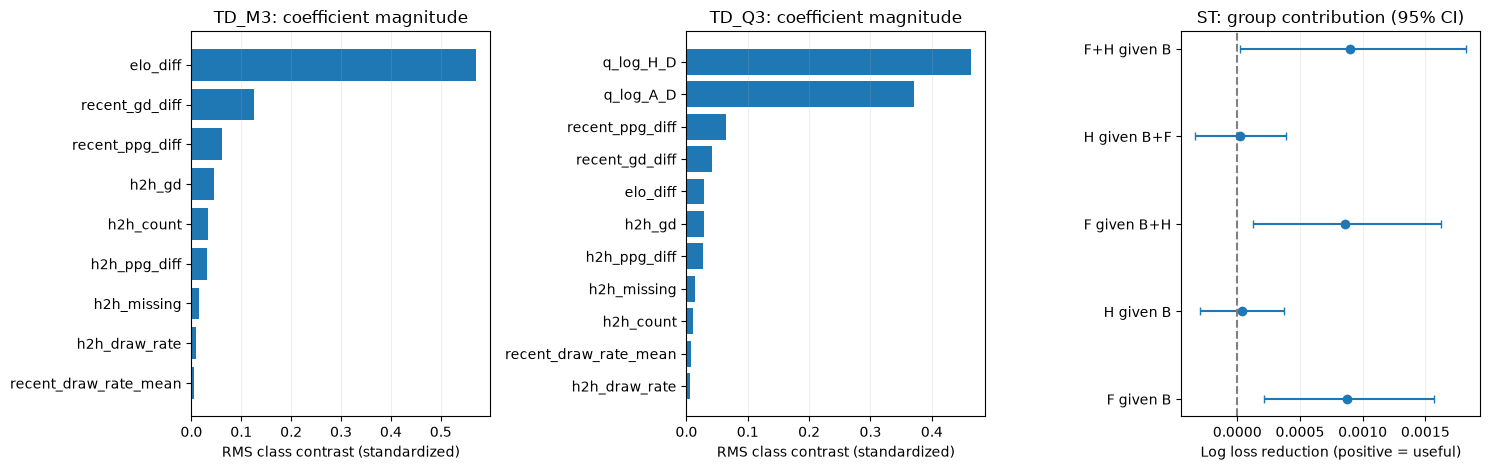

完成： /home/euan_li/projects/AML/reports/post_analysis/RESULTS.zh-CN.md


In [7]:
fig,axes=plt.subplots(1,3,figsize=(15,4.8))
for ax,name in zip(axes[:2],['TD_M3','TD_Q3']):
    frame=coefficients.loc[coefficients.model.eq(name)].sort_values('contrast_rms')
    ax.barh(frame.feature,frame.contrast_rms);ax.set_title(name+': coefficient magnitude');ax.set_xlabel('RMS class contrast (standardized)');ax.grid(axis='x',alpha=.2)
frame=contributions.loc[contributions.family.eq('ST network')&contributions.target.eq('outcome')].copy()
axes[2].errorbar(frame.gain,np.arange(len(frame)),xerr=np.maximum(0,np.array([frame.gain-frame.ci_low,frame.ci_high-frame.gain])),fmt='o',capsize=3)
axes[2].set_yticks(np.arange(len(frame)),frame.added_information);axes[2].axvline(0,color='gray',linestyle='--');axes[2].set_title('ST: group contribution (95% CI)');axes[2].set_xlabel('Log loss reduction (positive = useful)');axes[2].grid(axis='x',alpha=.2)
fig.tight_layout();fig.savefig(OUT/'interpretation.png',dpi=170,bbox_inches='tight');plt.show()

def md_table(frame):
    lines=['| '+' | '.join(map(str,frame.columns))+' |','| '+' | '.join(['---']*len(frame.columns))+' |']
    for values in frame.itertuples(index=False,name=None):
        lines.append('| '+' | '.join(f'{v:.6f}' if isinstance(v,(float,np.floating)) else str(v) for v in values)+' |')
    return '\n'.join(lines)
coef=coefficients.loc[coefficients.model.eq('TD_M3')]
report='# 模型权重与贡献解释\n\n'
report+='已读取22个逻辑回归模型、保存的神经网络预测和历史缓存。这里解释已训练结果，不改变模型。\n\n'
report+='## 1. 哪些数字可以称作权重\n\n逻辑回归每个输入有H/D/A三个系数；时间衰减有每场历史的固定权重；多任务有损失权重λ。LSTM没有一个可直接解释为近期/交锋百分比的参数，所以使用之前独立训练的对照模型衡量信息贡献。\n\n'
report+='## 2. 时间衰减逻辑回归的数值系数\n\n'
report+=md_table(coef[['meaning','beta_H','beta_D','beta_A','H_minus_A','ratio_H_A_per_SD','rank_within_model']])+'\n\n'
report+='数值输入已经标准化。H_minus_A是主胜与客胜系数之差；特征增加1个训练集标准差，其他输入固定时，p_H/p_A乘以ratio_H_A_per_SD。不是主胜概率增加这个比例。排序依据三种类别对比的均方根，不是百分比重要性；平局信息也纳入排序。联赛独热列另见logistic_division_coefficients.csv，使用E0作为解释参考。\n\n'
report+='## 3. 为什么近期积分差的系数为负\n\n'
report+=md_table(correlations)+'\n\n'
report+='近期积分差与近期净胜球差高度相关。当前系数描述在Elo、净胜球及其他输入固定时，积分差的条件关系；不能解释成赢球或积分越多越不好，也不建议仅凭负号删除。相关输入会分担信息，系数还受正则化影响。\n\n'
report+='## 4. 加入赔率后看什么\n\n'
report+=md_table(coefficients.loc[coefficients.model.eq('TD_Q3'),['meaning','H_minus_D','H_minus_A','D_minus_A','rank_within_model']])+'\n\n'
report+='赔率对数比的系数较大，Elo的额外系数缩小，与赔率已包含部分实力信息这一解释相符；不能据此证明博彩公司怎样制定赔率。所有22个模型的完整系数、训练标准差及原始单位系数见logistic_numeric_coefficients.csv。\n\n'
report+='## 5. 每场历史的时间权重\n\n'
report+=f'实际示例：{example.MatchDate.date()}，{example.HomeTeam} vs {example.AwayTeam}，SourceRow={int(example.SourceRow)}。详细每场日期、成绩、年龄和权重见time_weight_example.csv。\n\n'
report+=md_table(recent_weights)+'\n\n'
report+='顺序1→5为旧→新。每场比赛先单独归一化，再对测试集双方求平均。近期90天、交锋365天是人工固定半衰期；LSTM使用同样规则汇总隐藏向量，并未学出这些时间权重。较新隐藏向量仍可能记住较旧比赛，所以该表不是各场比赛对最终预测的完整贡献。\n\n'
report+='## 6. LSTM的近期和交锋贡献\n\n'
report+=md_table(contributions.loc[contributions.family.isin(['ST network','MT network'])&contributions.target.eq('outcome'),['family','added_information','gain','ci_low','ci_high','ci_includes_zero']])+'\n\n'
report+='gain=较少输入模型损失−增加信息后模型损失，正数表示改善；区间跨0表示这次比较还不确定。结果显示近期贡献更明确，交锋在已有近期信息后的额外贡献不明确。H指交锋成绩，交锋次数/缺失标记一直在B里。ST是单任务，MT是多任务；MT各输入组分别选λ，解释时需要考虑这一差异。完整逻辑回归/网络的赛果和赔率比较见group_contributions.csv。\n\n'
report+='## 7. 多任务损失权重\n\n'
report+=md_table(lambdas)+'\n\n'
report+='λ只乘在赔率损失上。λ=0.3不是30%的赔率贡献。损失数值占比也不等于梯度占比，因为两个损失如何改变网络参数还取决于梯度。\n\n'
report+='## 8. 使用范围\n\n这些是当前样本、已选模型的解释，不是因果结论。系数没有通过重新拟合bootstrap计算区间；贡献区间是按年分层的28天块bootstrap（1000次），未包含训练/选参不确定性，未校正多重比较。三个seed的集成减少了部分初始化波动。测试期已被查看；若据此删特征或调参，应回到训练/验证期，再用新的留出数据检验。没有在本Notebook进行概率校准。\n'
(OUT/'RESULTS.zh-CN.md').write_text(report,encoding='utf-8')
print('完成：',OUT/'RESULTS.zh-CN.md')